# Global coastal operability: existing results

This notebook **only reads** the independent `operability-workspace/`.
It does not submit CDS requests, start Dask workers, or calculate missing
scientific indicators. A fresh workspace initially shows zero downloaded data.

Use the root processing script for bounded sessions:

```bash
.venv/bin/python process_global.py run --hours 2 --workers 2 --max-requests 4
```

The script prints the live **Dask dashboard** URL (normally
http://127.0.0.1:8787/status). That dashboard exists during a session; the local
SQLite registry and exported progress tables persist afterwards. CDS acquisition
is sequential, so Dask workers may be idle while the service prepares data.

Reconstructed screening results are not measured port productivity or an exact
numerical replication of the publication. Missing observations are never filled.
No standalone HTML file is exported.


In [1]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

from operability.workspace import Registry
from operability.analysis import (
    available_periods, load_land, make_map, plot_availability,
    plot_progress, read_progress, read_results,
)

WORKSPACE = Path("operability-workspace")
PERIOD = "year_2025"  # Change to an available period listed below.
SCENARIO = "baseline"
METHOD_SIGNATURE = None  # None accepts one stored version; select explicitly if versions differ.
COUNTRIES = []  # Empty means all countries; e.g. ["South Africa"].

with Registry(WORKSPACE, read_only=True) as registry:
    config = registry.config
    print("Local progress database:", registry.database)
    print("Plan:", config["years"][0], "to", config["years"][-1],
          "-", len(registry.sites), "frozen coastal points")
    print("Requested period:", PERIOD)

land = load_land(WORKSPACE)
progress = read_progress(WORKSPACE)
if COUNTRIES:
    unknown = set(COUNTRIES) - set(progress.country)
    if unknown:
        raise ValueError(f"No saved coastal points for: {sorted(unknown)}")
    progress = progress.loc[progress.country.isin(COUNTRIES)].copy()


/Users/mvankoningsveld/Library/CloudStorage/OneDrive-DelftUniversityofTechnology/github/Port-Operability-Metocean/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Local progress database: /Users/mvankoningsveld/Library/Application Support/Port-Operability-Metocean/c3732f36e68147f5a3dcc72bd2eb0450/progress.sqlite3
Plan: 1979 to 2025 - 4013 frozen coastal points
Requested period: year_2025


## Central administration

`extraction_status` concerns the entire configured time span, not just `PERIOD`.
For example, one downloaded year of a 47-year plan is **partial**, even when that
year's calculation is complete. `source_gap_hours` counts missing/invalid
observations **within verified caches**; these do not trigger repeated downloads.

Run `process_global.py reconcile` after restoring files or an interrupted
session. It rebuilds a missing local database from the frozen inputs, request
records, monthly cache receipts and point-product archives.


,,,points
continent,extraction_status,analysis_status,
Africa,missing,waiting,513
Asia,missing,waiting,1190
Europe,missing,waiting,738
North America,missing,waiting,723
Oceania,missing,waiting,472
South America,missing,waiting,377


,site_id,country,continent,extraction_status,extracted_months,retained_months,raw_status,expected_months,valid_hours,source_gap_hours,analysis_status,completed_analyses,expected_analyses
0,839,Chile,South America,missing,0,0,missing,564,0,0,waiting,0,49
1,840,Chile,South America,missing,0,0,missing,564,0,0,waiting,0,49
2,841,Chile,South America,missing,0,0,missing,564,0,0,waiting,0,49
3,842,Chile,South America,missing,0,0,missing,564,0,0,waiting,0,49
4,853,Chile,South America,missing,0,0,missing,564,0,0,waiting,0,49
5,854,Chile,South America,missing,0,0,missing,564,0,0,waiting,0,49
6,855,Chile,South America,missing,0,0,missing,564,0,0,waiting,0,49
7,856,Chile,South America,missing,0,0,missing,564,0,0,waiting,0,49
8,858,Argentina,South America,missing,0,0,missing,564,0,0,waiting,0,49
9,874,Chile,South America,missing,0,0,missing,564,0,0,waiting,0,49


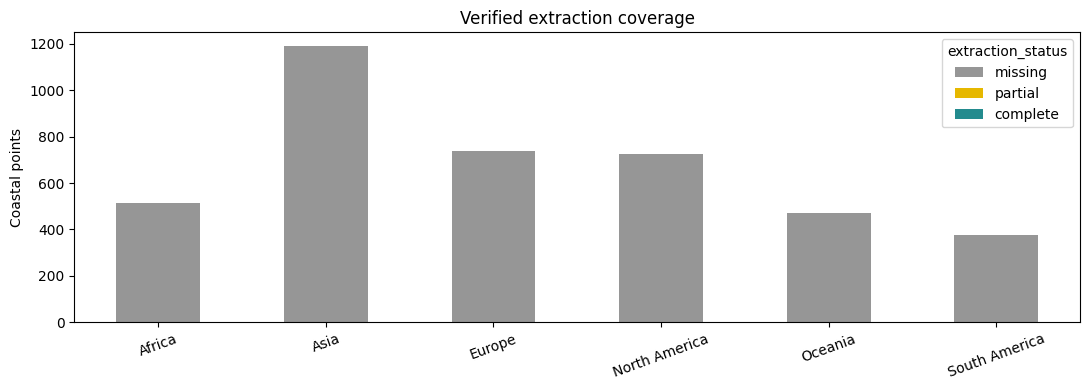

No processing session has been started in this fresh workspace.


In [2]:
display(progress.groupby(["continent", "extraction_status", "analysis_status"]).size()
        .rename("points").to_frame())
display(progress[["site_id", "country", "continent", "extraction_status",
                  "extracted_months", "retained_months", "raw_status", "expected_months",
                  "valid_hours", "source_gap_hours",
                  "analysis_status", "completed_analyses", "expected_analyses"]].head(30))
plot_progress(progress)
plt.show()

session_file = WORKSPACE / "progress/session.json"
if session_file.exists():
    session = json.loads(session_file.read_text())
    print("Last recorded session (not a process-liveness check):", session["status"])
    print("Dashboard during that session:", session.get("dashboard", "Not started"))
else:
    print("No processing session has been started in this fresh workspace.")


In [3]:
display(make_map(progress, land, kind="progress"))

## Available calculations

Each completed point-period includes all nine scenarios, overall statistics,
annual statistics and seasonal statistics. Long-term periods are calculated
from their continuous hourly histories, **not averages of annual availability**:
shutdown events and short calm gaps can cross calendar boundaries.

The helpers read verified **stored** products, even after raw files or the
progress database have been removed. Stored methods are labelled, and different
method versions are not silently mixed. Edit `PERIOD`, `SCENARIO`,
`METHOD_SIGNATURE` and `COUNTRIES` above to explore other selections.


In [4]:
display(available_periods(WORKSPACE))
summary = read_results(WORKSPACE, PERIOD, method_signature=METHOD_SIGNATURE)
annual = read_results(WORKSPACE, PERIOD, "annual", method_signature=METHOD_SIGNATURE)
seasonal = read_results(WORKSPACE, PERIOD, "seasonal", method_signature=METHOD_SIGNATURE)
if COUNTRIES and not summary.empty:
    summary = summary.loc[summary.country.isin(COUNTRIES)].copy()
    annual = annual.loc[annual.country.isin(COUNTRIES)].copy()
    seasonal = seasonal.loc[seasonal.country.isin(COUNTRIES)].copy()

if summary.empty:
    print(f"No completed calculations yet for {PERIOD} and this country selection.")
    print("Run the processing script; then rerun this notebook. No values are fabricated.")
else:
    print("Stored method signature:", summary.method_signature.iloc[0])
    selected = summary.loc[summary.scenario.eq(SCENARIO)]
    display(selected[["site_id", "country", "total_availability", "risk", "main_driver",
                      "frequency", "duration", "coverage_fraction"]])
    display(summary.groupby("scenario").total_availability.agg(["count", "min", "mean", "max"]))
    plot_availability(summary, seasonal, scenario=SCENARIO)
    plt.show()
    if annual.year.nunique() > 1:
        annual.loc[annual.scenario.eq(SCENARIO)].groupby("year").total_availability.mean().plot(
            figsize=(10, 3), ylabel="Mean availability (%)", title=f"Annual screening - {PERIOD}")
        plt.show()


,period,method_signature,completed_points


No completed calculations yet for year_2025 and this country selection.
Run the processing script; then rerun this notebook. No values are fabricated.


## Calculated Folium map

Only processed points appear here. Click a marker for indicator availability,
dominant driver, event statistics and coverage. The background is embedded
Natural Earth geometry; no tile service or API key is needed. The legend folds.


In [5]:
if not summary.empty:
    display(make_map(summary, land, kind="availability", scenario=SCENARIO))
else:
    print("The calculated map will appear when point results are available.")

The calculated map will appear when point results are available.


## Reuse and extend

- `operability/workspace.py`: frozen configuration, coverage ledger, integrity,
  resume/rebuild and compressed point-product archives.
- `operability/processing.py`: bounded CDS acquisition, Dask workers and
  calculation/checkpoint scheduling.
- `operability/products.py`: atomic checkpoints, plain CSV/gzip exports and
  provenance, independent of raw data.
- `operability/analysis.py`: read-only loading, figures and Folium maps.
- `port_operability.py`: shared scientific transformations and event definitions.

For example, `read_results(WORKSPACE, PERIOD)` returns an ordinary pandas
DataFrame for custom analysis. `make_map(...)` returns a Folium object. Add new
analysis cells or extend the shared helpers instead of copying the downloader.
The files under `inputs/` are frozen; use a different workspace to change the grid
or target years.

Portable tables live in `products/tables/site-<id>/`: `summary.csv.gz`,
`annual.csv.gz`, `seasonal.csv.gz` and `provenance.json`. pandas reads these
directly. Keep `products/`, `intermediate/coverage/`, `inputs/` and
`workspace.json` when removing raw NetCDF caches. Do not remove input history
until all intended long-term calculations are complete: those cannot be
reconstructed by averaging annual summaries.
